In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np // Importing numpy Python library for numerical calculations, arrays, math operations

import pandas as pd // Importing Python library for working with tables/dataframes and Excel style data

import matplotlib.pyplot as plt // Import library for creating charts and plots

import seaborn as sns // library for more cohesive statistical charts built on top of matplotlib

In [63]:
# Load the real estate dataset from the project's data folder
realtor_df = pd.read_csv("../data/realtor-data.zip.csv")

display(realtor_df.head())


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


### Load the dataset

The dataset is stored in the project's `data` folder. Using a relative path keeps the notebook portable so it can run outside Google Colab as long as the repository structure is preserved.


In [64]:
size = realtor_df.size

shape = realtor_df.shape

print("Size = {}\nShape = {}".format(size, shape))
print('Rows: ', realtor_df.shape[0])
print('Cols: ', realtor_df.shape[1])

Size = 26716584
Shape = (2226382, 12)
Rows:  2226382
Cols:  12


df = pd.read_csv("realtor-data.zip.csv", nrows=100000) // large file, so this loads only the first 100,000 rows at first to test

size = df.size // calculates the total number of cells in the dataset by multiplying rows by columns

shape = df.shape // gets the shape of the dataset, which shows the number of rows and columns

print("Size = {}\nShape = {}".format(size, shape)) // prints the total number of cells and the shape of the dataset

print('Rows: ', df.shape[0]) // prints the number of rows in the dataset

print('Cols: ', df.shape[1]) // prints the number of columns in the dataset

In [65]:
# Basic statistics
print("\nBasic Statistics:")
print(realtor_df.describe())


Basic Statistics:
        brokered_by         price           bed          bath      acre_lot  \
count  2.221849e+06  2.224841e+06  1.745065e+06  1.714611e+06  1.900793e+06   
mean   5.293989e+04  5.241955e+05  3.275841e+00  2.496440e+00  1.522303e+01   
std    3.064275e+04  2.138893e+06  1.567274e+00  1.652573e+00  7.628238e+02   
min    0.000000e+00  0.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00   
25%    2.386100e+04  1.650000e+05  3.000000e+00  2.000000e+00  1.500000e-01   
50%    5.288400e+04  3.250000e+05  3.000000e+00  2.000000e+00  2.600000e-01   
75%    7.918300e+04  5.500000e+05  4.000000e+00  3.000000e+00  9.800000e-01   
max    1.101420e+05  2.147484e+09  4.730000e+02  8.300000e+02  1.000000e+05   

             street      zip_code    house_size  
count  2.215516e+06  2.226083e+06  1.657898e+06  
mean   1.012325e+06  5.218668e+04  2.714471e+03  
std    5.837635e+05  2.895408e+04  8.081635e+05  
min    0.000000e+00  0.000000e+00  4.000000e+00  
25%    5.063128e+05

print("\nBasic Statistics:") // prints a title before the statistics table; \n adds a blank line before the title

print(df.describe()) // displays basic statistics for the numeric columns, including count, mean, standard deviation, minimum, maximum, and quartiles

In [66]:
# Counts of missing values
print("\nMissing Values Count:")
print(realtor_df.isnull().sum())


Missing Values Count:
brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
city                1407
state                  8
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64



print("\nMissing Values Count:") // prints a title before the missing values count; \n adds a blank line before the title

print(realtor_df.isnull().sum()) // checks each column in the real estate dataset and counts how many missing/null values are in each column

In [67]:
# Make a copy of the original dataset so the raw data is preserved
realtor_cleaned = realtor_df.copy()

# Remove duplicate rows from the dataset
realtor_cleaned = realtor_cleaned.drop_duplicates()

# Remove rows where price is missing because price is one of the most important columns for analysis
realtor_cleaned = realtor_cleaned.dropna(subset=['price'])

# Fill missing numeric values with the median value of each column
# Median is used because it is less affected by very high or very low outliers
numeric_columns = ['bed', 'bath', 'acre_lot', 'house_size']

for col in numeric_columns:
    realtor_cleaned[col] = realtor_cleaned[col].fillna(realtor_cleaned[col].median())

# Fill missing categorical/text values with "Unknown"
categorical_columns = ['brokered_by', 'street', 'city', 'zip_code', 'prev_sold_date']

for col in categorical_columns:
    realtor_cleaned[col] = realtor_cleaned[col].fillna('Unknown')

# Convert previous sold date to a datetime format
# The format='%Y-%m-%d' tells Pandas the date is written as year-month-day
realtor_cleaned['prev_sold_date'] = pd.to_datetime(
    realtor_cleaned['prev_sold_date'],
    format='%Y-%m-%d',
    errors='coerce'
)

# Display the number of missing values after cleaning
print("\nMissing Values After Cleaning:")
print(realtor_cleaned.isnull().sum())

# Display the new shape of the cleaned dataset
print("\nCleaned Dataset Shape:")
print(realtor_cleaned.shape)


Missing Values After Cleaning:
brokered_by            0
status                 0
price                  0
bed                    0
bath                   0
acre_lot               0
street                 0
city                   0
state                  8
zip_code               0
house_size             0
prev_sold_date    733257
dtype: int64

Cleaned Dataset Shape:
(2224841, 12)


Make a copy of the original dataset so the raw data is preserved
realtor_cleaned = realtor_df.copy()

Remove duplicate rows from the dataset
realtor_cleaned = realtor_cleaned.drop_duplicates()

Remove rows where price is missing because price is one of the most important columns for analysis
realtor_cleaned = realtor_cleaned.dropna(subset=['price'])

Fill missing numeric values with the median value of each column
Median is used because it is less affected by very high or very low outliers
numeric_columns = ['bed', 'bath', 'acre_lot', 'house_size']

for col in numeric_columns:
    realtor_cleaned[col] = realtor_cleaned[col].fillna(realtor_cleaned[col].median())

Fill missing categorical/text values with "Unknown"
categorical_columns = ['brokered_by', 'street', 'city', 'zip_code', 'prev_sold_date']

for col in categorical_columns:
    realtor_cleaned[col] = realtor_cleaned[col].fillna('Unknown')

realtor_cleaned['prev_sold_date'] = pd.to_datetime(
    realtor_cleaned['prev_sold_date'],
    format='%Y-%m-%d',
    errors='coerce'
) // converts prev_sold_date into a real date format; format='%Y-%m-%d' tells Pandas the date pattern is year-month-day, and errors='coerce' changes invalid or missing dates into NaT

Display the number of missing values after cleaning
print("\nMissing Values After Cleaning:")
print(realtor_cleaned.isnull().sum())

Display the new shape of the cleaned dataset
print("\nCleaned Dataset Shape:")
print(realtor_cleaned.shape)

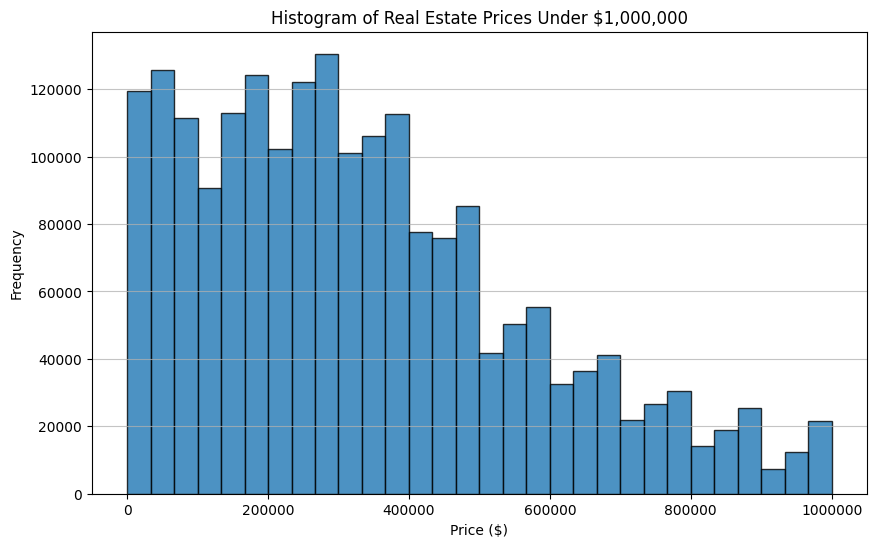

In [68]:
# Histogram of real estate price data under $1,000,000
price_filtered = realtor_cleaned[realtor_cleaned['price'] <= 1000000]

plt.figure(figsize=(10, 6))
plt.hist(price_filtered['price'], bins=30, edgecolor='black', alpha=0.8)
plt.title('Histogram of Real Estate Prices Under $1,000,000')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.ticklabel_format(style='plain', axis='x')  # Shows full dollar amounts instead of scientific notation
plt.savefig('real_estate_price_histogram_under_1m.png')
plt.show()

price_filtered = realtor_cleaned[realtor_cleaned['price'] <= 1000000] // creates a filtered dataset that only includes properties priced at $1,000,000 or less so extreme outliers do not distort the chart

plt.figure(figsize=(10, 6)) // creates a new chart and sets the size to 10 inches wide by 6 inches tall

plt.hist(price_filtered['price'], bins=30, edgecolor='black', alpha=0.8) // creates a histogram of property prices using 30 price ranges

plt.title('Histogram of Real Estate Prices Under 1,000,000') // adds a title to explain that the chart is filtered to homes under 1,000,000

plt.xlabel('Price ($)') // labels the x-axis as property price in dollars

plt.ylabel('Frequency') // labels the y-axis as frequency, showing how many properties fall into each price range

plt.grid(axis='y', alpha=0.75) // adds horizontal grid lines to make the chart easier to read

plt.ticklabel_format(style='plain', axis='x') // shows the x-axis price labels as regular numbers instead of scientific notation

plt.savefig('real_estate_price_histogram_under_1m.png') // saves the histogram as an image file

plt.show() // displays the histogram

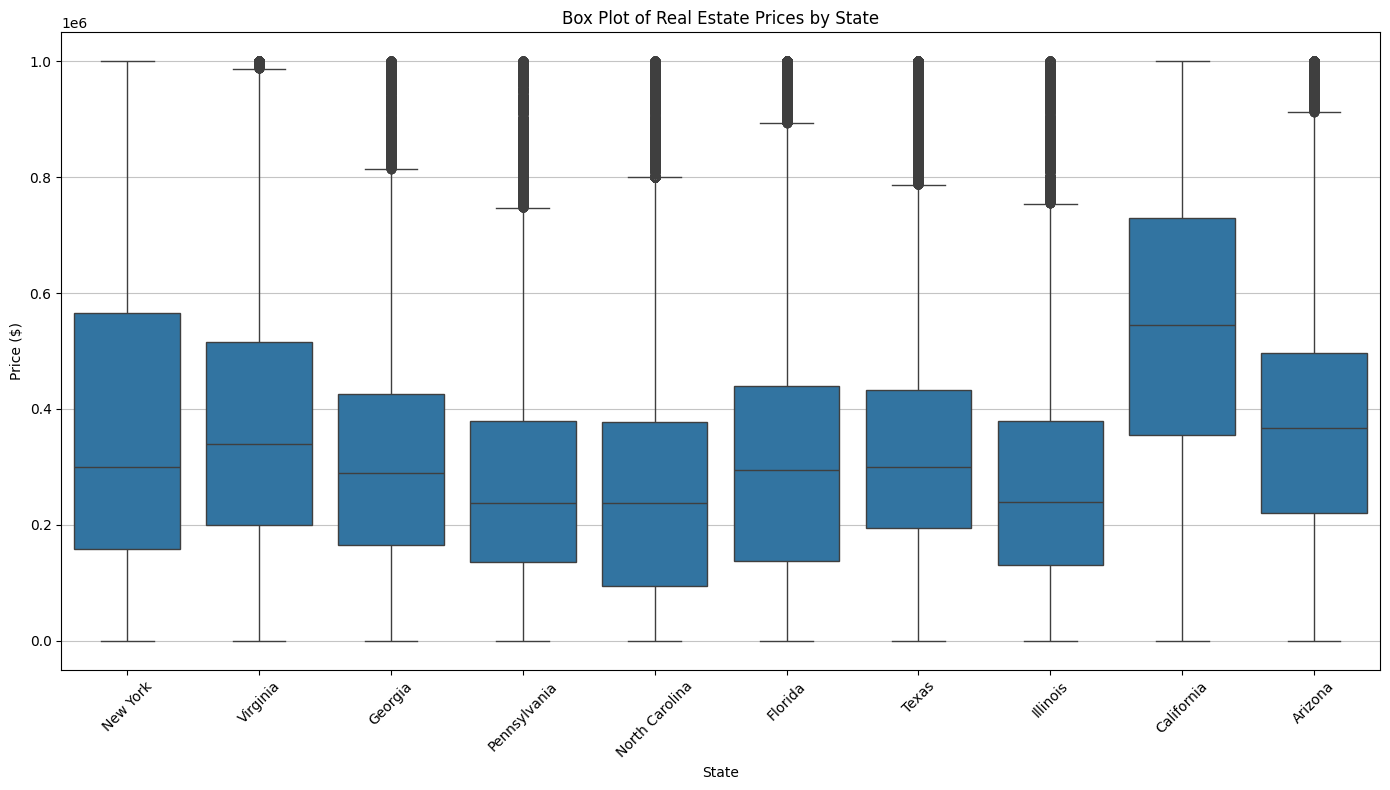

In [69]:
# Box plot of real estate prices by state

# Filter the cleaned dataset to remove extreme price outliers
price_filtered = realtor_cleaned[realtor_cleaned['price'] <= 1000000]

# Find the 10 states with the most property listings
top_states = price_filtered['state'].value_counts().head(10).index

# Keep only rows from those top 10 states
state_price_data = price_filtered[price_filtered['state'].isin(top_states)]

# Create the box plot
plt.figure(figsize=(14, 8))
sns.boxplot(x='state', y='price', data=state_price_data)
plt.title('Box Plot of Real Estate Prices by State')
plt.xlabel('State')
plt.ylabel('Price ($)')
plt.grid(axis='y', alpha=0.75)
plt.xticks(rotation=45)  # Rotate state labels for better readability
plt.tight_layout()  # Adjust layout to make room for rotated labels
plt.savefig('real_estate_price_boxplot_by_state.png')
plt.show()

Box plot of real estate prices by state // section label explaining that this chart compares property prices across states

price_filtered = realtor_cleaned[realtor_cleaned['price'] <= 1000000] // filters the cleaned dataset to only include properties priced at $1,000,000 or less so extreme outliers do not distort the chart

top_states = price_filtered['state'].value_counts().head(10).index // finds the 10 states with the highest number of property listings in the filtered dataset

state_price_data = price_filtered[price_filtered['state'].isin(top_states)] // keeps only the rows where the state is one of the top 10 states

plt.figure(figsize=(14, 8)) // creates a new chart and sets the size to 14 inches wide by 8 inches tall

sns.boxplot(x='state', y='price', data=state_price_data) // creates a box plot comparing real estate prices by state

plt.title('Box Plot of Real Estate Prices by State') // adds a title to the chart

plt.xlabel('State') // labels the x-axis as state

plt.ylabel('Price ($)') // labels the y-axis as property price in dollars

plt.grid(axis='y', alpha=0.75) // adds horizontal grid lines to make the price values easier to compare

plt.xticks(rotation=45) // rotates the state labels so they are easier to read

plt.tight_layout() // adjusts the chart layout so labels do not get cut off

plt.savefig('real_estate_price_boxplot_by_state.png') // saves the box plot as an image file

plt.show() // displays the box plot



In [70]:
# Identifying outliers in real estate price using Z-score
z_scores = np.abs((realtor_cleaned['price'] - realtor_cleaned['price'].mean()) / realtor_cleaned['price'].std())
outliers = realtor_cleaned[z_scores > 3]

print("\nOutliers in Real Estate Price (Z-score > 3):")
print(outliers[['status', 'price', 'bed', 'bath', 'acre_lot', 'city', 'state', 'house_size']])


Outliers in Real Estate Price (Z-score > 3):
           status       price  bed  bath  acre_lot          city        state  \
56       for_sale  10000000.0  6.0   5.0      0.12        Aguada  Puerto Rico   
124      for_sale   8000000.0  3.0   2.0    247.57       Isabela  Puerto Rico   
255      for_sale  11500000.0  4.0   5.0      1.98        Dorado  Puerto Rico   
378      for_sale  12000000.0  4.0   7.0      0.37        Dorado  Puerto Rico   
384      for_sale  16000000.0  4.0   7.0      0.75        Dorado  Puerto Rico   
...           ...         ...  ...   ...       ...           ...          ...   
2207691      sold   7900000.0  4.0   4.0     25.26  Orcas Island   Washington   
2211503      sold  12901148.0  3.0   2.0      0.70       Seattle   Washington   
2211738      sold   9880000.0  6.0   6.0      0.56        Medina   Washington   
2220811      sold   8500000.0  3.0   2.0    561.15    Moses Lake   Washington   
2221413      sold  12500000.0  5.0   3.0    957.26    Ellensbur

Identifying outliers in real estate price using Z-score // section label explaining that this code finds unusual property prices

z_scores = np.abs((realtor_cleaned['price'] - realtor_cleaned['price'].mean()) / realtor_cleaned['price'].std()) // calculates how far each property price is from the average price, measured in standard deviations

outliers = realtor_cleaned[z_scores > 3] // filters the dataset to keep only properties where the price is more than 3 standard deviations away from the average

print("\nOutliers in Real Estate Price (Z-score > 3):") // prints a title before displaying the outlier records

print(outliers[['status', 'price', 'bed', 'bath', 'acre_lot', 'city', 'state', 'house_size']]) // displays selected columns for the outlier properties so they are easier to review

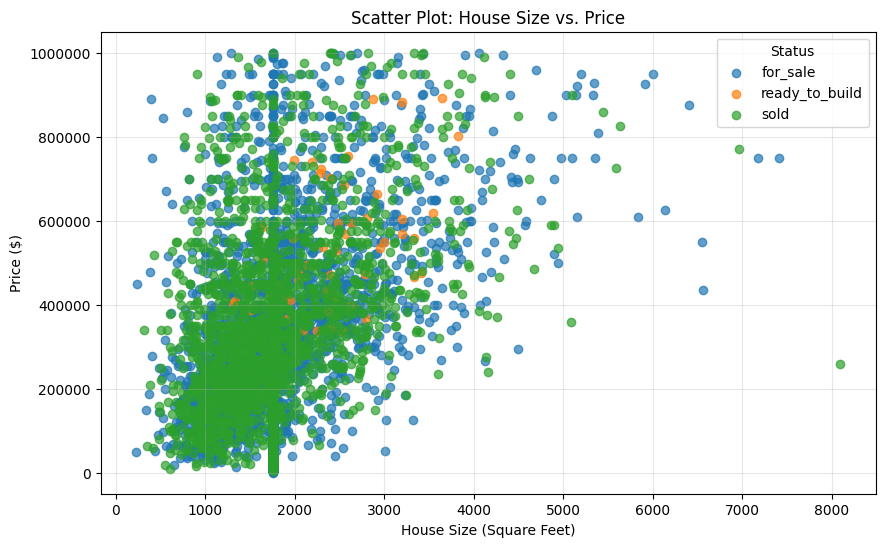

In [71]:
# Scatter plot of house size vs. price using a sample of the data

scatter_data = realtor_cleaned[
    (realtor_cleaned['price'] <= 1000000) &
    (realtor_cleaned['house_size'] <= 10000)
]

scatter_sample = scatter_data.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 6))

for status, group in scatter_sample.groupby('status'):
    plt.scatter(group['house_size'], group['price'], label=status, alpha=0.7)

plt.title('Scatter Plot: House Size vs. Price')
plt.xlabel('House Size (Square Feet)')
plt.ylabel('Price ($)')
plt.legend(title='Status', loc='upper right')
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='both')
plt.savefig('house_size_price_scatter.png')
plt.show()


scatter_data = realtor_cleaned[(realtor_cleaned['price'] <= 1000000) &
(realtor_cleaned['house_size'] <= 10000)
] // filters the cleaned dataset to only include properties priced at $1,000,000 or less and homes that are 10,000 square feet or smaller so extreme outliers do not distort the chart

scatter_sample = scatter_data.sample(n=5000, random_state=42) // takes a random sample of 5,000 rows from the filtered data so the scatter plot runs faster and is easier to read

plt.figure(figsize=(10, 6)) // creates a new chart and sets the size to 10 inches wide by 6 inches tall

for status, group in scatter_sample.groupby('status'): // groups the sample data by property status so each status can be plotted separately

plt.scatter(group['house_size'], group['price'], label=status, alpha=0.7) // creates a scatter plot using house size on the x-axis and price on the y-axis; alpha=0.7 makes the points slightly transparent

plt.title('Scatter Plot: House Size vs. Price') // adds a title to the chart

plt.xlabel('House Size (Square Feet)') // labels the x-axis as house size in square feet

plt.ylabel('Price ($)') // labels the y-axis as property price in dollars

plt.legend(title='Status', loc='upper right') // adds a legend showing the property status groups and places it in the upper right corner

plt.grid(True, alpha=0.3) // adds light grid lines to make the chart easier to read

plt.ticklabel_format(style='plain', axis='both') // displays the axis numbers in regular format instead of scientific notation

plt.savefig('house_size_price_scatter.png') // saves the scatter plot as an image file

plt.show() // displays the scatter plot

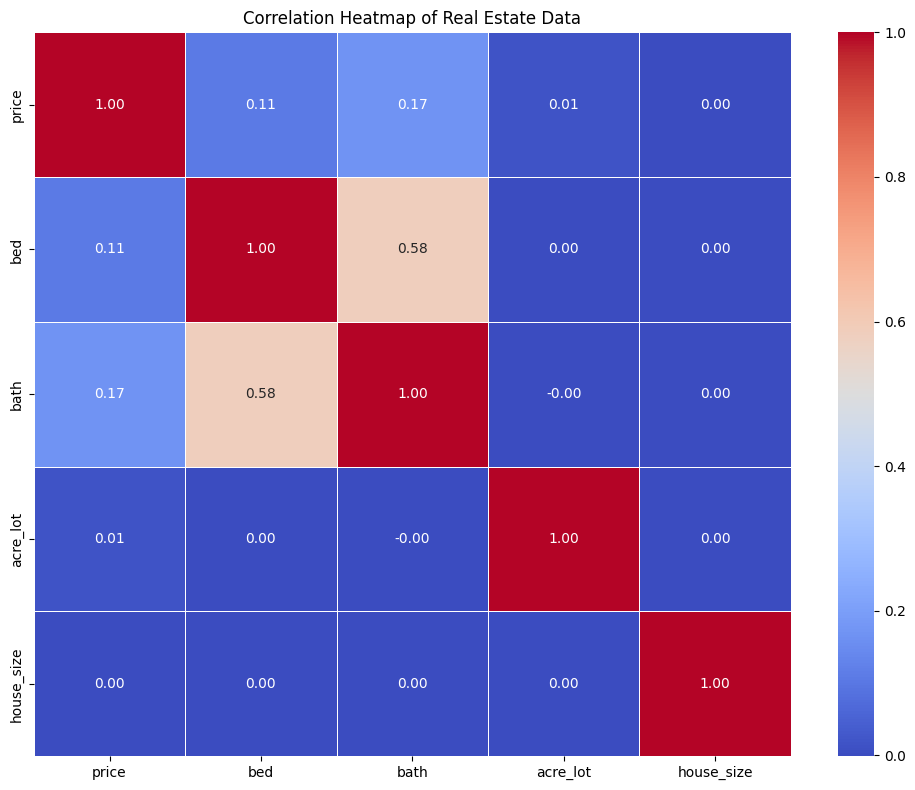

In [72]:
# Correlation heatmap for real estate data
plt.figure(figsize=(10, 8))
correlation = realtor_cleaned.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Real Estate Data')
plt.tight_layout()
plt.savefig('real_estate_correlation_heatmap.png')
plt.show()

plt.figure(figsize=(10, 8)) // creates a new chart and sets the size to 10 inches wide by 8 inches tall

correlation = realtor_cleaned.select_dtypes(include=[np.number]).corr() // selects only the numeric columns from the cleaned real estate dataset and calculates the correlation between them

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5) // creates a heatmap of the correlation values; annot=True displays the numbers, fmt='.2f' rounds them to two decimals, and linewidths adds spacing between cells

plt.title('Correlation Heatmap of Real Estate Data') // adds a title to the chart

plt.tight_layout() // adjusts the layout so labels and titles fit neatly

plt.savefig('real_estate_correlation_heatmap.png') // saves the heatmap as an image file

plt.show() // displays the heatmap